# MNIST VAE training


In [1]:
import torch
from torch.utils.data import DataLoader
from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor

from hsp.plotting import LossPlotter
from hsp.vae import VAE

torch.manual_seed(0)

## Load MNIST


In [2]:
mnist_train = MNIST(root="data", train=True, download=True, transform=ToTensor())
data_loader = DataLoader(mnist_train, batch_size=64, shuffle=True)

images, labels = next(iter(data_loader))
data = images.flatten(start_dim=1)
print(data.shape)  # torch.Size([64, 784])

torch.Size([64, 784])


## Create the VAE


In [3]:
vae = VAE(input_dim=784, latent_dim=16, hidden_dim=128, num_layers=3)
optimizer = torch.optim.Adam(vae.parameters(), lr=0.001)

## Train

For every mini-batch, flatten the images, run the VAE, calculate its loss, and update the weights. The numeric loss from each training step is stored for the plot.

In [4]:
losses = []
reconstruction_losses = []
kl_losses = []

vae.train()

for epoch in range(15):

    epoch_loss = 0
    epoch_reconstruction = 0
    epoch_kl = 0
    num_samples = 0

    for images, _ in data_loader:

        data = images.flatten(start_dim=1)

        reconstruction, mu, logvar = vae(data)

        loss, reconstruction_loss, kl_divergence = vae.loss(
            reconstruction,
            data,
            mu,
            logvar
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Accumulate losses
        batch_size = data.size(0)

        epoch_loss += loss.item() * batch_size
        epoch_reconstruction += reconstruction_loss.item() * batch_size
        epoch_kl += kl_divergence.item() * batch_size

        num_samples += batch_size

    # Calculate average losses
    avg_loss = epoch_loss / num_samples
    avg_reconstruction = epoch_reconstruction / num_samples
    avg_kl = epoch_kl / num_samples

    losses.append(avg_loss)
    reconstruction_losses.append(avg_reconstruction)
    kl_losses.append(avg_kl)

    print(
        f"Epoch {epoch + 1:02d} | "
        f"Total: {avg_loss:.4f} | "
        f"Reconstruction: {avg_reconstruction:.4f} | "
        f"KL: {avg_kl:.4f}"
    )

Epoch 01 | Total: 190.1093 | Reconstruction: 186.0490 | KL: 4.0603
Epoch 02 | Total: 150.6159 | Reconstruction: 142.5422 | KL: 8.0737
Epoch 03 | Total: 134.6365 | Reconstruction: 123.9545 | KL: 10.6820
Epoch 04 | Total: 126.8350 | Reconstruction: 115.0903 | KL: 11.7447
Epoch 05 | Total: 123.5112 | Reconstruction: 111.4210 | KL: 12.0902
Epoch 06 | Total: 121.2974 | Reconstruction: 108.9647 | KL: 12.3326
Epoch 07 | Total: 119.7706 | Reconstruction: 107.2758 | KL: 12.4948
Epoch 08 | Total: 118.5772 | Reconstruction: 105.9320 | KL: 12.6452
Epoch 09 | Total: 117.6131 | Reconstruction: 104.8481 | KL: 12.7650
Epoch 10 | Total: 116.8534 | Reconstruction: 103.9818 | KL: 12.8716
Epoch 11 | Total: 116.1607 | Reconstruction: 103.2169 | KL: 12.9438
Epoch 12 | Total: 115.5895 | Reconstruction: 102.5774 | KL: 13.0121
Epoch 13 | Total: 115.1412 | Reconstruction: 102.0613 | KL: 13.0799
Epoch 14 | Total: 114.6873 | Reconstruction: 101.5699 | KL: 13.1175
Epoch 15 | Total: 114.2634 | Reconstruction: 101.1

## Plot the loss

The notebook delegates plotting to the library class instead of constructing a Matplotlib graph itself.

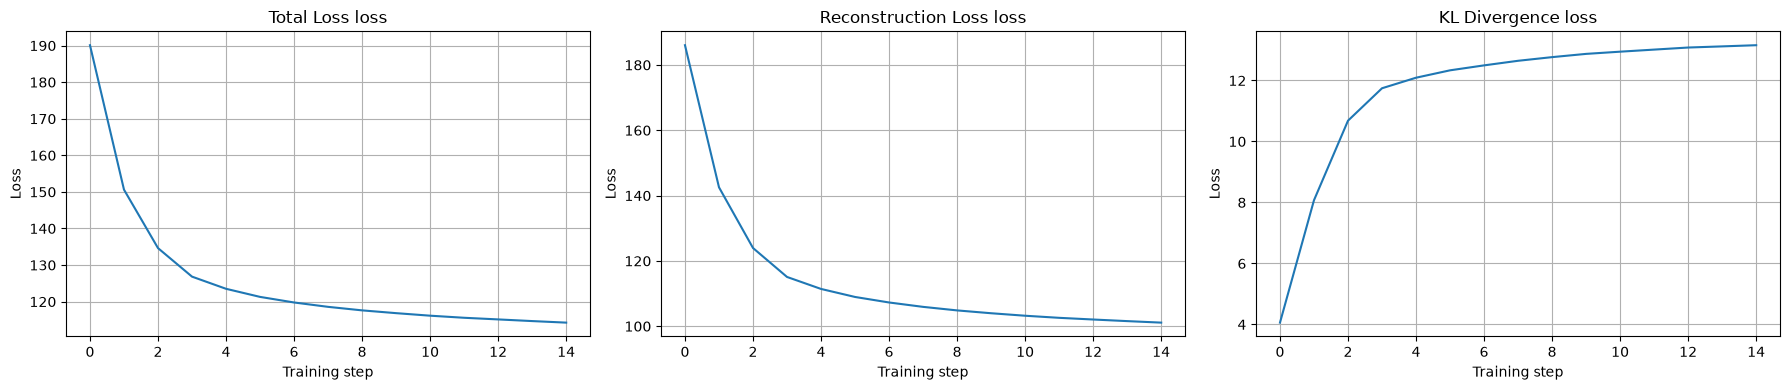

In [5]:
LossPlotter().plot({
    "Total Loss": losses,
    "Reconstruction Loss": reconstruction_losses,
    "KL Divergence": kl_losses
})[0]

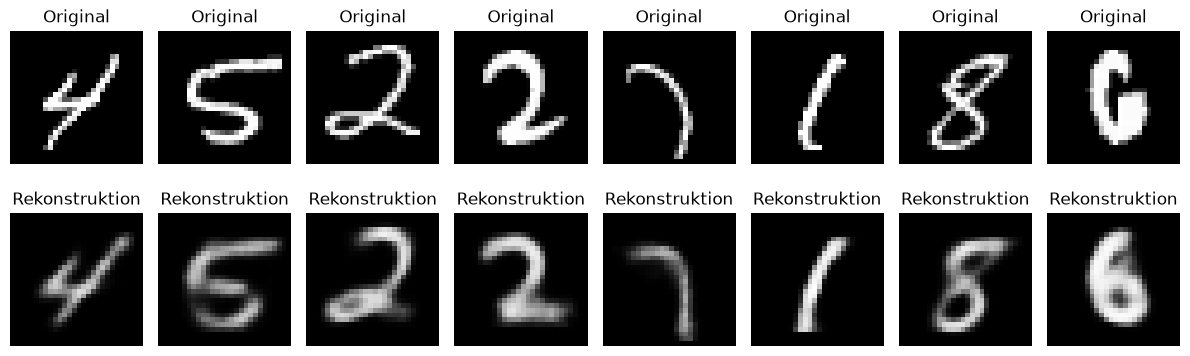

In [6]:
import matplotlib.pyplot as plt

vae.eval()

images, _ = next(iter(data_loader))
data = images.flatten(start_dim=1)

with torch.no_grad():
    reconstruction, mu, logvar = vae(data)

reconstruction = torch.sigmoid(reconstruction)
reconstruction = reconstruction.reshape(-1, 1, 28, 28)

fig, axes = plt.subplots(2, 8, figsize=(12, 4))

for i in range(8):
    axes[0, i].imshow(images[i].squeeze(), cmap="gray")
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

    axes[1, i].imshow(
        reconstruction[i].squeeze().cpu().numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[1, i].set_title("Rekonstruktion")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()